# Compare regulons and iModulons

In [1]:
# imports
import pandas as pd
import os
from os import path

import matplotlib.pyplot as plt

from pymodulon.io import *

In [2]:
# matplotlib default font
plt.rcParams['font.family'] = 'serif'
# Specify a preferred fallback list of fonts
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

### path to different data

In [ ]:
data_dir = path.join('..', 'ctherm_nf','processed_data')

### load the icadata object

In [ ]:
# load the data
ica_data = load_json_model(path.join(data_dir, 'ctherm.json.gz')) #adjusted
# also need enrichment data
df_enrichments = pd.read_csv(path.join(data_dir,'functional_enrichments.csv'), index_col=0)

/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/p

### First rename the imodulons

In [ ]:
df_rename_imod = pd.read_csv('./results_characterize_imodulons/imod_rename_mapping.tsv', sep='\t', index_col=0)
dict_rename_imod = df_rename_imod[['IM']].to_dict()['IM']

# rename all at once
ica_data.rename_imodulons(dict_rename_imod)

# set IM as index for this work
df_rename_imod.set_index('IM', inplace=True)

# GRN for regulation in C. thermocellum
for i,row in ica_data.imodulon_table.iterrows():
    if pd.notnull(row.regulator):
        ica_data.imodulon_table.loc[i, 'category'] = 'regulatory'
    else:
        ica_data.imodulon_table.loc[i, 'category'] = df_rename_imod.loc[i, 'category']



### Create regulon data from icadata object for the recall plot

In [10]:
df_reg = ica_data.imodulon_table.loc[~ica_data.imodulon_table.regulator.isna()]
df_reg = df_reg[['precision', 'recall', 'TP', 'regulon_size', 'imodulon_size']]

df_reg.rename(columns={'regulon_size': 'target_set_size'}, inplace=True)

df_reg['target_size_frac'] = df_reg['TP'].div(df_reg['target_set_size'])
df_reg['im_size_frac'] = df_reg['TP'].div(df_reg['imodulon_size'])
df_reg

,precision,recall,TP,target_set_size,imodulon_size,target_size_frac,im_size_frac
SigI6,0.241379,0.583333,7.0,12.0,29,0.583333,0.241379
BlaI_0696,0.150000,0.750000,3.0,4.0,20,0.750000,0.150000
GlyR3,0.428571,1.000000,3.0,3.0,7,1.000000,0.428571
Rex_2471,0.875000,0.071429,7.0,98.0,8,0.071429,0.875000


In [12]:
reg_interested = ['LexA_1449', 'TetR_0692'] # these are the ones that were based on the GRN
df_reg_added = df_enrichments.loc[df_enrichments.annotation.isin(reg_interested)]

#
df_reg_added.set_index('imodulon', inplace=True)
df_reg_added = df_reg_added.loc[df_reg_added.index.isin([46, 54])]

In [ ]:
# now add the required metrics to df_reg_added
for imod in df_reg_added.index.to_list():
    
    row_of_interest = df_reg_added.loc[imod]

    imod_name = row_of_interest['annotation']

    TP = row_of_interest['TP']
    precision = row_of_interest['precision']
    recall = row_of_interest['recall']
    reg_size = row_of_interest['target_set_size']
    imod_size = row_of_interest['imodulon_size']
    frac_reg = TP/reg_size
    frac_im = TP/imod_size
    
    df_reg.loc[imod_name] = precision, recall, TP, reg_size, imod_size, frac_reg, frac_im

df_reg

### Comparing the imodulon with regulon recalls

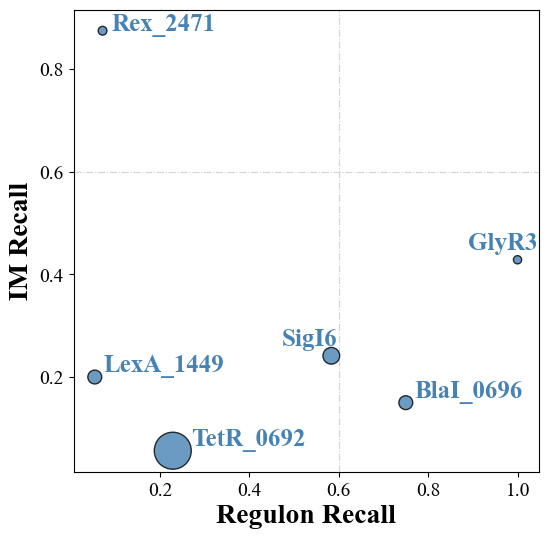

In [ ]:
fig, ax = plt.subplots(figsize=(6,6))

# threshold for IMs vs regulons
pt=0.6
ax.axhline(pt, linestyle="-.", color='lightgrey', linewidth=0.8)
ax.axvline(pt, linestyle="-.", color='lightgrey', linewidth=0.8)

ax.scatter(df_reg.recall, df_reg.precision,  s=df_reg.imodulon_size*5, #for bigger size of the circles
                     c='steelblue',  alpha=0.8, edgecolors='black',
                     zorder=2) #zorder to make sure the points are above the gridlines

ax.set_xlabel("Regulon Recall", fontdict={'size':20, 'weight':'bold'})
ax.set_ylabel("IM Recall", fontdict={'size':20, 'weight':'bold'})


# adding labels/texts within the plot
labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_reg.iterrows():

    # default
    x_ax = row['recall'] + 0.02
    y_ax = row['precision'] + 0.01

    if imod in ['Rex_2471']:
        x_ax = row['recall'] + 0.02
        y_ax = row['precision']
    elif imod in ['TetR_0692']:
        x_ax = row['recall'] + 0.04
        y_ax = row['precision'] + 0.01
    elif imod in ['GlyR3', 'SigI6']:
            x_ax = row['recall'] - 0.11
            y_ax = row['precision'] + 0.02
        
    ax.text(x_ax, y_ax,
            imod, fontsize=18, fontweight='bold', color="steelblue")

ax.tick_params(labelsize=14)

# plt.savefig('./results_characterize_imodulons/precision_recall_regulon_imodulon.png', transparent=True, pad_inches=0.01, dpi=300, format='png')
plt.show()

# FIN